In [1]:
import os
import numpy as np
import pandas as pd

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("khushikyad001/india-gdp-loss-during-covid-19")

print("Path to dataset files:", path)

100%|██████████| 128k/128k [00:00<00:00, 47.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/khushikyad001/india-gdp-loss-during-covid-19/versions/1


In [3]:
path = "/root/.cache/kagglehub/datasets/khushikyad001/india-gdp-loss-during-covid-19/versions/1"

In [4]:
files = os.listdir(path)
print('Files in directory',files)

Files in directory ['india_gdp_loss_covid_simulated.csv']


In [5]:
csv_path = os.path.join(path, files[0])
df = pd.read_csv(csv_path)

In [6]:
df

,Date,State,Sector,GDP_Before_COVID,GDP_During_COVID,GDP_Loss_Percent,Unemployment_Rate_Before,Unemployment_Rate_During,Migration_Effect,Recovery_Factor,Govt_Support_Received,Sector_Impact_Score,Health_Index,Lockdown_Severity,Vaccination_Rate,Urban_Rural_Ratio,Inflation_Rate,Population_Affected,Recovery_Progress,Remarks
0,2019-01-01,Himachal Pradesh,Transport,38079.47,33876.70,11.04,5.76,13.188781,0,0.55,797.03,2,56.35,5,28.52,2.08,7.24,453.69,96.16,High Impact
1,2019-01-31,Karnataka,Manufacturing,95120.72,82525.28,13.24,6.31,16.638936,1,0.72,797.03,3,41.95,4,79.29,0.48,8.83,285.24,41.15,High Impact
2,2019-03-02,Maharashtra,Mining,73467.40,58827.93,19.93,8.98,12.230889,1,0.90,797.03,6,53.35,4,93.77,2.06,4.01,440.24,88.13,High Impact
3,2019-04-01,Meghalaya,Mining,60267.19,56326.71,6.54,5.38,8.677830,1,0.90,797.03,1,54.92,1,77.91,1.91,5.46,412.09,96.37,Low Impact
4,2019-05-01,Bihar,Mining,16445.85,11021.45,32.98,9.09,16.658184,0,0.33,797.03,2,60.87,4,60.56,1.53,3.57,40.81,94.89,Low Impact
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2022-11-11,Rajasthan,Transport,49740.22,45466.99,8.59,3.55,14.126560,0,0.32,797.03,7,43.61,3,2.76,1.60,7.05,26.83,86.79,High Impact
2496,2019-01-01,Tripura,Transport,58150.62,37320.10,35.82,3.51,14.485088,1,0.99,797.03,4,74.21,4,55.47,1.98,4.96,334.59,43.91,Low Impact
2497,2019-01-31,Tripura,Finance,86692.14,61962.77,28.53,8.95,20.417079,1,0.68,797.03,1,53.69,5,16.95,1.95,6.28,137.30,41.06,Low Impact
2498,2019-03-02,Tamil Nadu,Manufacturing,98093.20,86862.60,11.45,4.49,10.464880,1,0.73,797.03,3,39.56,4,0.10,0.57,5.67,10.83,84.79,Medium Impact


In [7]:
df.nunique()

,0
Date,48
State,28
Sector,10
GDP_Before_COVID,2500
GDP_During_COVID,2500
GDP_Loss_Percent,1747
Unemployment_Rate_Before,683
Unemployment_Rate_During,2500
Migration_Effect,2
Recovery_Factor,101


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      2500 non-null   object 
 1   State                     2500 non-null   object 
 2   Sector                    2500 non-null   object 
 3   GDP_Before_COVID          2500 non-null   float64
 4   GDP_During_COVID          2500 non-null   float64
 5   GDP_Loss_Percent          2500 non-null   float64
 6   Unemployment_Rate_Before  2500 non-null   float64
 7   Unemployment_Rate_During  2500 non-null   float64
 8   Migration_Effect          2500 non-null   int64  
 9   Recovery_Factor           2500 non-null   float64
 10  Govt_Support_Received     2500 non-null   float64
 11  Sector_Impact_Score       2500 non-null   int64  
 12  Health_Index              2500 non-null   float64
 13  Lockdown_Severity         2500 non-null   int64  
 14  Vaccinat

#***We are focusing mostly on GDP loss and Unemployement as inflation rate of the whole country remains uniform throught the year***

#***OBSERVATIONS -***
- There are no null or missing values.
- Govt_Support_Received	is constant for every state and sector as std is very less.
- Datatype of date is given as Object (DISCRETE).

SUPPORTING ARGUMENTS

In [9]:
df.isnull().sum()

,0
Date,0
State,0
Sector,0
GDP_Before_COVID,0
GDP_During_COVID,0
GDP_Loss_Percent,0
Unemployment_Rate_Before,0
Unemployment_Rate_During,0
Migration_Effect,0
Recovery_Factor,0


In [10]:
df[df.duplicated()]    ##No duplicates

,Date,State,Sector,GDP_Before_COVID,GDP_During_COVID,GDP_Loss_Percent,Unemployment_Rate_Before,Unemployment_Rate_During,Migration_Effect,Recovery_Factor,Govt_Support_Received,Sector_Impact_Score,Health_Index,Lockdown_Severity,Vaccination_Rate,Urban_Rural_Ratio,Inflation_Rate,Population_Affected,Recovery_Progress,Remarks


In [11]:
df['Govt_Support_Received'].std()

2.410643136548077e-11

#PROBLEM - 1
- SOLUTION ---> Datetime Transformation


In [12]:
df['Date'].dtype     ##Object

dtype('O')

In [13]:
pd.to_datetime(df['Date'],dayfirst = True,format = 'mixed') ## dates in form of 1,2,3 are taken in YYYYMMDD so format='mixed is used.

,Date
0,2019-01-01
1,2019-01-31
2,2019-03-02
3,2019-04-01
4,2019-05-01
...,...
2495,2022-11-11
2496,2019-01-01
2497,2019-01-31
2498,2019-03-02


In [14]:
df['Date'].min()

'2019-01-01'

In [15]:
df['Date'].max()

'2022-11-11'

In [16]:
df.describe()

,GDP_Before_COVID,GDP_During_COVID,GDP_Loss_Percent,Unemployment_Rate_Before,Unemployment_Rate_During,Migration_Effect,Recovery_Factor,Govt_Support_Received,Sector_Impact_Score,Health_Index,Lockdown_Severity,Vaccination_Rate,Urban_Rural_Ratio,Inflation_Rate,Population_Affected,Recovery_Progress
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2.500000e+03,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,50388.948344,39027.999640,22.682540,6.455488,13.348877,0.514400,0.495612,7.970300e+02,5.499600,61.951484,3.072000,51.553892,1.612960,5.951224,245.012532,55.104844
std,28797.659499,23136.158122,10.094722,2.014139,3.456965,0.499893,0.292699,2.410643e-11,2.892429,18.598983,1.399571,29.174740,0.800848,1.716269,141.649731,26.188689
min,1154.950000,760.710000,5.020000,3.000000,5.251729,0.000000,0.000000,7.970300e+02,1.000000,30.010000,1.000000,0.000000,0.200000,3.000000,1.170000,10.010000
25%,25003.075000,18835.060000,13.950000,4.710000,10.836281,0.000000,0.240000,7.970300e+02,3.000000,45.747500,2.000000,27.035000,0.920000,4.470000,122.855000,31.712500
50%,51081.200000,38907.835000,22.760000,6.400000,13.295331,1.000000,0.480000,7.970300e+02,6.000000,61.900000,3.000000,52.325000,1.620000,5.950000,242.950000,54.860000
75%,75223.170000,57139.692500,31.370000,8.190000,15.828844,1.000000,0.760000,7.970300e+02,8.000000,77.522500,4.000000,77.062500,2.290000,7.400000,367.030000,78.017500
max,99972.050000,94373.350000,40.000000,10.000000,21.661447,1.000000,1.000000,7.970300e+02,10.000000,94.920000,5.000000,99.990000,3.000000,9.000000,499.870000,99.970000


#***OBSERVATIONS*** -
##1.The average GDP(50%) dropped from 50,388.95 before COVID to 39,027.99 during COVID.
##2.All the regions and sectors suffered a loss of 22% GDP, 40% loss was seen 108 times in Tripura.
##3*.Though the std(GDP) decreased from 29k to 23k. The coefficient of variance (std/mean) is higher in after covid case hence gap between different economy classes grew ---> Inflation rate reached maximum of 9%.
##4.The average Unemployement rate grew by 100% that is from 6% ---> 13%.

In [17]:
cv_1 = ((df.groupby('State')['GDP_Before_COVID'].std()/df.groupby('State')['GDP_Before_COVID'].mean())*100).mean()

In [18]:
cv_1

np.float64(57.25251294290627)

In [19]:
cv_2 = ((df.groupby('State')['GDP_During_COVID'].std()/df.groupby('State')['GDP_During_COVID'].mean())*100).mean()

In [20]:
cv_2

np.float64(59.34520093318774)

In [21]:
cv_1 < cv_2

np.True_

In [22]:
worst_hit= df[df['GDP_Loss_Percent'] == 40]

In [23]:
worst_hit['State'].value_counts()

,count
State,
Himachal Pradesh,1
Rajasthan,1
Nagaland,1


In [24]:
most_hit= df[df['GDP_Loss_Percent'] <= 40]
most_hit['State'].value_counts()

,count
State,
Tripura,108
Madhya Pradesh,106
Haryana,106
Tamil Nadu,103
Sikkim,101
Punjab,100
Assam,96
Himachal Pradesh,95
Goa,95


In [25]:
unemployment_comparison = df.groupby('State')[['Unemployment_Rate_Before', 'Unemployment_Rate_During']].mean()
unemployment_comparison


,Unemployment_Rate_Before,Unemployment_Rate_During
State,,
Andhra Pradesh,6.404894,12.894488
Arunachal Pradesh,6.528395,13.752744
Assam,6.025729,12.783299
Bihar,6.632043,13.839430
Chhattisgarh,6.639103,13.195953
Delhi,6.666203,13.512151
Goa,6.765895,13.474387
Gujarat,6.103548,13.165310
Haryana,6.705943,13.463063


<Axes: xlabel='State'>

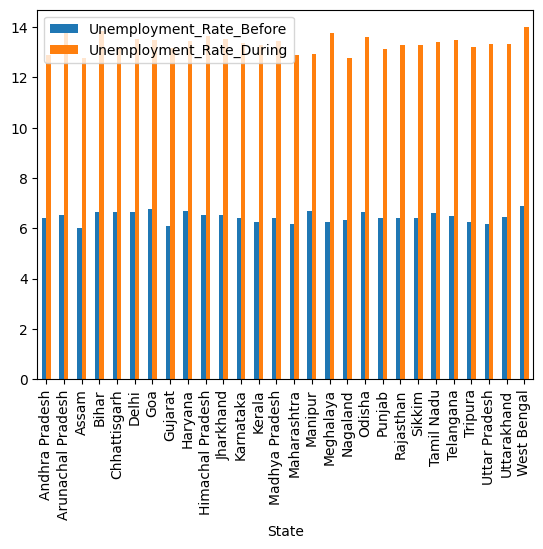

In [26]:
unemployment_comparison.plot(kind='bar')

#***CREATING GROUPS FOR GDP EVALUATION***

##PROBLEM-
SOLUTION ---> Each state had different sectors (parameters for evaluation are more) instead of dropping them we can group State-wise GDP using groupby and sum() function.

In [27]:
df.columns

Index(['Date', 'State', 'Sector', 'GDP_Before_COVID', 'GDP_During_COVID',
       'GDP_Loss_Percent', 'Unemployment_Rate_Before',
       'Unemployment_Rate_During', 'Migration_Effect', 'Recovery_Factor',
       'Govt_Support_Received', 'Sector_Impact_Score', 'Health_Index',
       'Lockdown_Severity', 'Vaccination_Rate', 'Urban_Rural_Ratio',
       'Inflation_Rate', 'Population_Affected', 'Recovery_Progress',
       'Remarks'],
      dtype='object')

In [28]:
GDP_Before = df.groupby('State')['GDP_Before_COVID'].sum()

In [29]:
GDP_Before

,GDP_Before_COVID
State,
Andhra Pradesh,5124498.47
Arunachal Pradesh,4303286.33
Assam,5047209.02
Bihar,4166310.17
Chhattisgarh,3774905.53
Delhi,3731683.91
Goa,4918132.81
Gujarat,4784300.53
Haryana,4827393.41


<Axes: xlabel='State'>

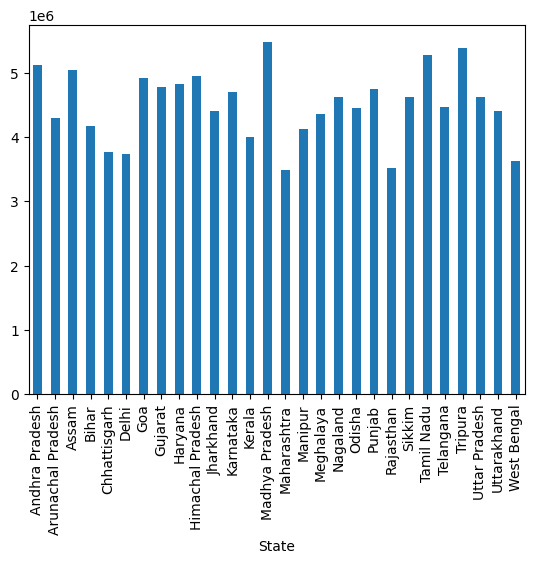

In [30]:
GDP_Before.plot(kind = 'bar')

In [31]:
GDP_during = df.groupby('State')['GDP_During_COVID'].sum()

In [32]:
GDP_during

,GDP_During_COVID
State,
Andhra Pradesh,3935941.51
Arunachal Pradesh,3389714.94
Assam,3886933.07
Bihar,3161955.21
Chhattisgarh,2883024.93
Delhi,2915516.59
Goa,3791996.45
Gujarat,3667202.59
Haryana,3709806.27


<Axes: xlabel='State'>

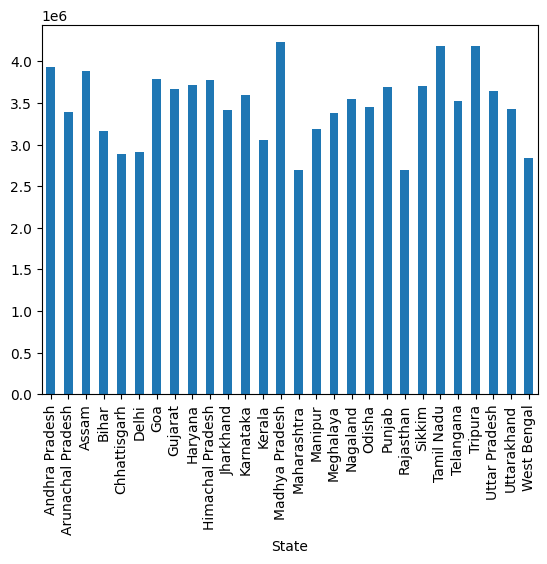

In [33]:
GDP_during.plot(kind = 'bar')

In [34]:
##joining gdp before and after to plot comparision graph

In [35]:
m = pd.merge(GDP_during,GDP_Before,how = 'inner',on = 'State')

<Axes: xlabel='State'>

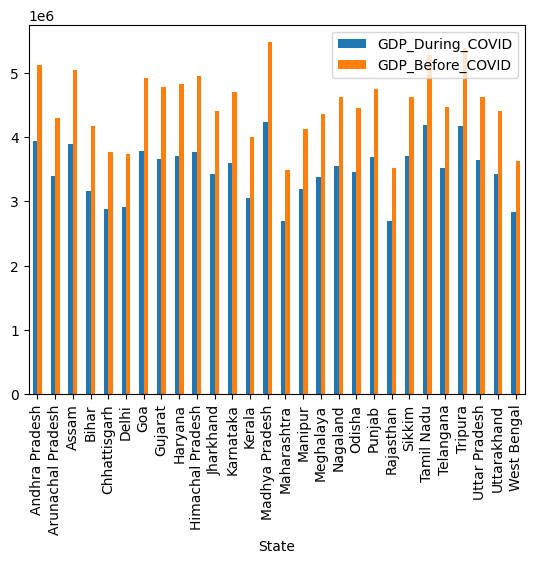

In [36]:
m.plot(kind='bar')

#IMPACT-WISE SECREGATION

<Axes: xlabel='Sector'>

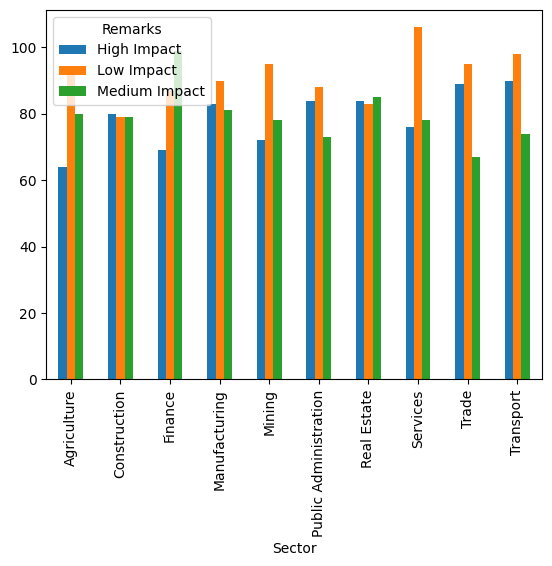

In [37]:
pd.crosstab(df['Sector'],df['Remarks']).plot(kind='bar')     ##cat vs cat

<Axes: xlabel='State'>

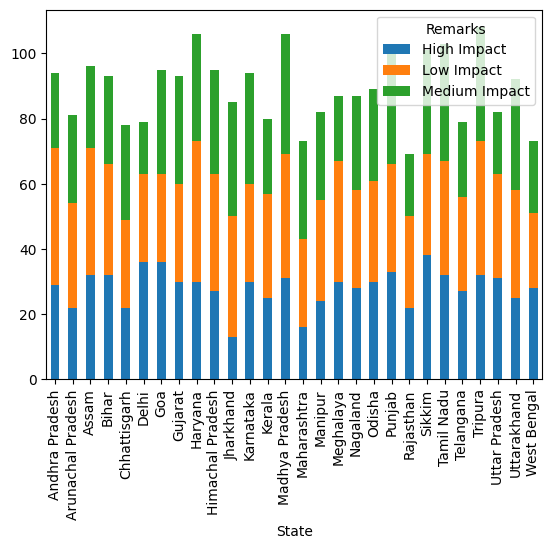

In [38]:
pd.crosstab(df['State'],df['Remarks']).plot(kind='bar',stacked=True)

In [39]:
df.columns

Index(['Date', 'State', 'Sector', 'GDP_Before_COVID', 'GDP_During_COVID',
       'GDP_Loss_Percent', 'Unemployment_Rate_Before',
       'Unemployment_Rate_During', 'Migration_Effect', 'Recovery_Factor',
       'Govt_Support_Received', 'Sector_Impact_Score', 'Health_Index',
       'Lockdown_Severity', 'Vaccination_Rate', 'Urban_Rural_Ratio',
       'Inflation_Rate', 'Population_Affected', 'Recovery_Progress',
       'Remarks'],
      dtype='object')

In [40]:
recover = df.groupby('State')['Recovery_Factor'].mean()

In [41]:
recover

,Recovery_Factor
State,
Andhra Pradesh,0.507447
Arunachal Pradesh,0.518765
Assam,0.526562
Bihar,0.515269
Chhattisgarh,0.460641
Delhi,0.534177
Goa,0.517579
Gujarat,0.483656
Haryana,0.517358


In [42]:
(df.groupby('State')['Health_Index'].mean()).mean()

np.float64(61.94014055048148)

#Bivariate Analysis

##1. GDP Before vs During COVID

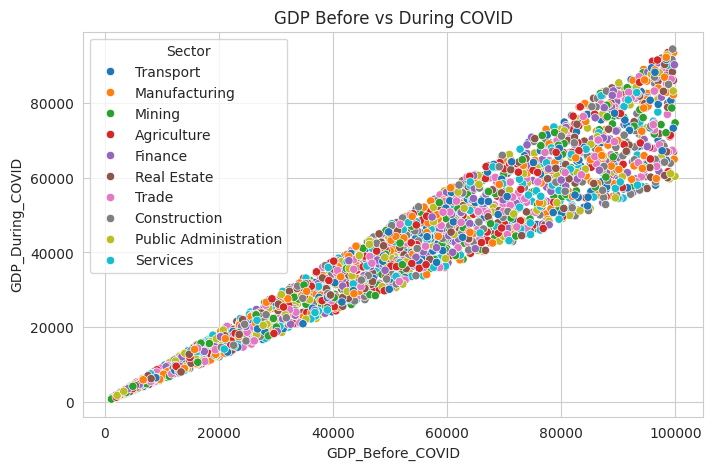

In [44]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="GDP_Before_COVID",
                y="GDP_During_COVID", hue="Sector")

plt.title("GDP Before vs During COVID")
plt.show()

##2. Unemployment Before vs During COVID

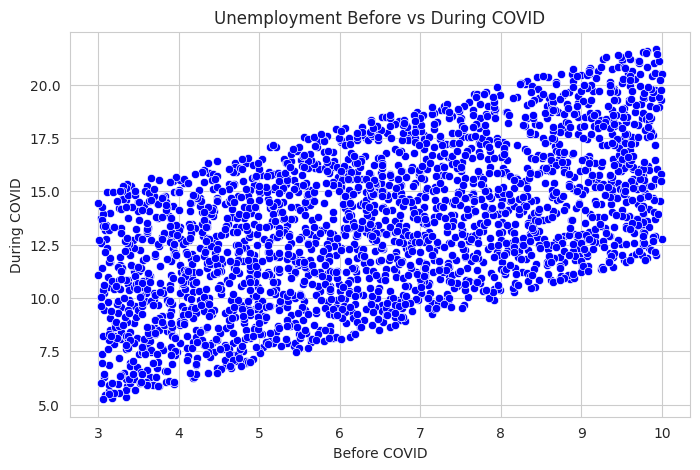

In [45]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Unemployment_Rate_Before",
                y="Unemployment_Rate_During", color="blue")

plt.title("Unemployment Before vs During COVID")
plt.xlabel("Before COVID")
plt.ylabel("During COVID")
plt.show()

##3. GDP Loss vs Recovery Progress

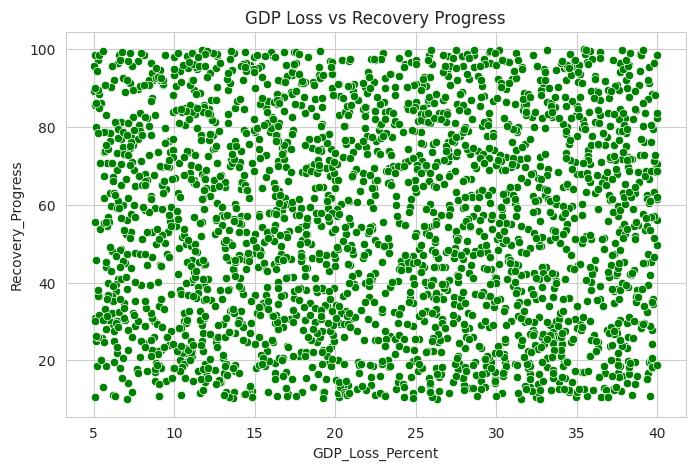

-0.015994402332596493


In [46]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="GDP_Loss_Percent",
                y="Recovery_Progress", color="green")

plt.title("GDP Loss vs Recovery Progress")
plt.show()

print(df["GDP_Loss_Percent"].corr(df["Recovery_Progress"]))

##4. Average GDP Loss by Sector

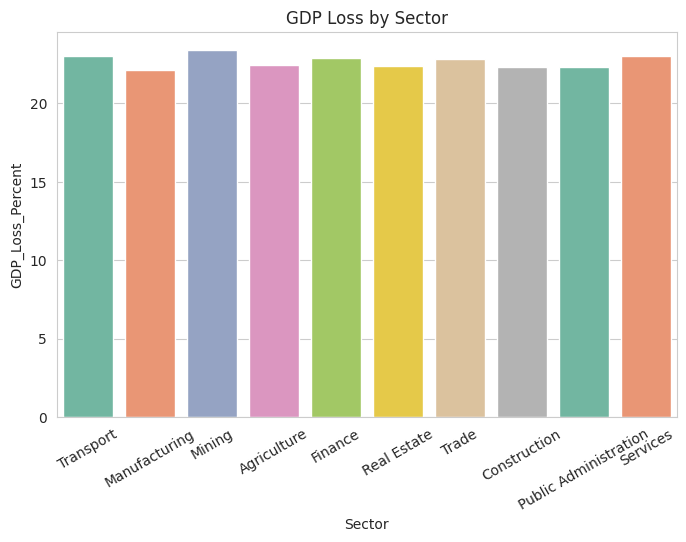

In [47]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Sector", y="GDP_Loss_Percent",
            hue="Sector", palette="Set2", legend=False,
            errorbar=None)

plt.title("GDP Loss by Sector")
plt.xticks(rotation=30)
plt.show()

##5. Top 10 States with Highest GDP Loss

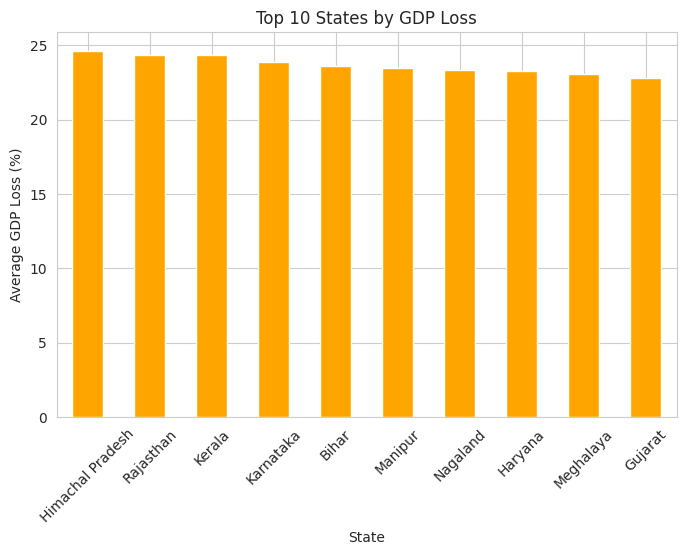

In [48]:
loss = df.groupby("State")["GDP_Loss_Percent"].mean()
loss = loss.sort_values(ascending=False).head(10)

loss.plot(kind="bar", figsize=(8, 5), color="orange")

plt.title("Top 10 States by GDP Loss")
plt.ylabel("Average GDP Loss (%)")
plt.xticks(rotation=45)
plt.show()

##6. Correlation Heatmap

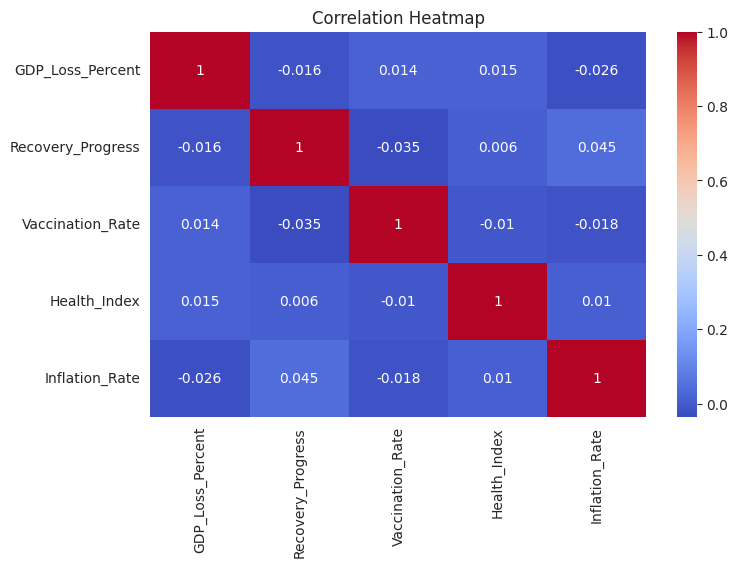

In [49]:
cols = ["GDP_Loss_Percent", "Recovery_Progress",
        "Vaccination_Rate", "Health_Index",
        "Inflation_Rate"]

plt.figure(figsize=(8, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()